In [56]:
"""
H&M Consumer Behavior Analysis
Notebook 03: Predictive Modeling with Explainability

Purpose: Build interpretable ML models for business decision-making
Models: Random Forest (High-Value Prediction), Logistic Regression (Churn Prediction)

Author: [Your Name]
Date: 2024

Business Objectives:
1. Predict high-value customers from early purchase behavior
2. Identify churn risk for proactive retention
3. Provide explainable insights for business stakeholders
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import joblib
import warnings
warnings.filterwarnings('ignore')

# Scikit-learn imports
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve)
from sklearn.preprocessing import StandardScaler

# Configuration
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.4f}'.format)

# Paths
DATA_PATH = Path('../data/processed')
FEATURES_PATH = Path('../data/features')
MODELS_PATH = Path('../models')
FIGURES_PATH = Path('../reports/figures')
TABLES_PATH = Path('../reports/tables')

MODELS_PATH.mkdir(parents=True, exist_ok=True)

print("="*80)
print("PREDICTIVE MODELING - EXPLAINABLE ML")
print("="*80)
print("\nLibraries loaded successfully")
print(f"Scikit-learn version: {__import__('sklearn').__version__}")

PREDICTIVE MODELING - EXPLAINABLE ML

Libraries loaded successfully
Scikit-learn version: 1.7.2


In [57]:
print("\nLoading RFM feature dataset...")

rfm = pd.read_parquet(FEATURES_PATH / "rfm_features.parquet")

print(f"Customers loaded: {len(rfm):,}")
print("\nColumns available:")
print(rfm.columns.tolist())

rfm.head()


Loading RFM feature dataset...
Customers loaded: 1,362,281

Columns available:
['customer_id', 'recency', 'frequency', 'monetary', 'R_score', 'F_score', 'M_score', 'segment', 'segment_encoded', 'high_value']


,customer_id,recency,frequency,monetary,R_score,F_score,M_score,segment,segment_encoded,high_value
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,18,21,0.6490,4,3,3,Champions,5,1
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,77,86,2.6019,3,4,4,Champions,5,1
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,8,18,0.7048,4,3,4,Champions,5,1
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,472,2,0.0610,1,1,1,Lost,1,0
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,42,13,0.4697,4,3,3,Champions,5,1


In [58]:
# ============================================================
# LOAD REQUIRED DATA FOR MODELING
# ============================================================

print("\nLoading transaction and RFM datasets...")

# Load transaction-level data
df = pd.read_csv("transactions_train.csv", parse_dates=["t_dat"])

# Load RFM features (with target variable)
rfm = pd.read_parquet(FEATURES_PATH / "rfm_features.parquet")

print(f"Transactions loaded: {len(df):,}")
print(f"Customers loaded (RFM): {len(rfm):,}")
print(f"Date range: {df['t_dat'].min()} to {df['t_dat'].max()}")

df.head()


Loading transaction and RFM datasets...
Transactions loaded: 31,788,324
Customers loaded (RFM): 1,362,281
Date range: 2018-09-20 00:00:00 to 2020-09-22 00:00:00


,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,663713001,0.0508,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,541518023,0.0305,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221004,0.0152,2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687003,0.0169,2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687004,0.0169,2


In [59]:
# ============================================================
# CELL 3: CUSTOMER-LEVEL FEATURE ENGINEERING (UPDATED)
# ============================================================

print("\nEngineering customer-level features...")

# ------------------------------------------------------------
# 1️ First Purchase Characteristics
# ------------------------------------------------------------

first_purchase = (
    df.sort_values('t_dat')
      .groupby('customer_id')
      .first()
      .reset_index()
)

first_purchase = first_purchase[
    ['customer_id', 'price', 'sales_channel_id']
]

first_purchase.columns = [
    'customer_id',
    'first_purchase_amount',
    'first_channel'
]

# ------------------------------------------------------------
# 2️ Behavioral Aggregations
# ------------------------------------------------------------

customer_behavior = (
    df.groupby('customer_id')
      .agg({
          'price': ['mean', 'std', 'min', 'max'],
          'article_id': 'nunique',
          't_dat': ['min', 'max', 'count'],
          'sales_channel_id': lambda x: x.mode()[0] if len(x) > 0 else 1
      })
      .reset_index()
)

customer_behavior.columns = [
    'customer_id',
    'avg_order_value',
    'std_order_value',
    'min_order',
    'max_order',
    'unique_products',
    'first_purchase_date',
    'last_purchase_date',
    'price',
    'preferred_channel'
]

# ------------------------------------------------------------
# 3️ Derived Behavioral Metrics
# ------------------------------------------------------------

customer_behavior['customer_lifespan'] = (
    customer_behavior['last_purchase_date'] -
    customer_behavior['first_purchase_date']
).dt.days

customer_behavior['purchase_frequency'] = (
    customer_behavior['price'] /
    (customer_behavior['customer_lifespan'] + 1)
)

# Replace possible NaN std values
customer_behavior['std_order_value'] = (
    customer_behavior['std_order_value'].fillna(0)
)

# ------------------------------------------------------------
# 4️ Merge Everything (INCLUDING monetary)
# ------------------------------------------------------------

customer_features = customer_behavior.merge(
    first_purchase,
    on='customer_id',
    how='left'
)

customer_features = customer_features.merge(
    rfm[['customer_id', 'recency', 'frequency', 'monetary',
         'segment', 'segment_encoded']],
    on='customer_id',
    how='left'
)

print("\nFeature engineering complete")
print(f"Customers: {len(customer_features):,}")
print(f"Total features: {len(customer_features.columns)}")

print("\nFinal columns:")
print(customer_features.columns.tolist())


Engineering customer-level features...

Feature engineering complete
Customers: 1,362,281
Total features: 19

Final columns:
['customer_id', 'avg_order_value', 'std_order_value', 'min_order', 'max_order', 'unique_products', 'first_purchase_date', 'last_purchase_date', 'price', 'preferred_channel', 'customer_lifespan', 'purchase_frequency', 'first_purchase_amount', 'first_channel', 'recency', 'frequency', 'monetary', 'segment', 'segment_encoded']


In [60]:
# ============================================================
# CREATE TARGET VARIABLES
# ============================================================

print("\nCreating target variables...")

# ------------------------------------------------------------
# Target 1: is_high_value
# Customers in the top 20% by total monetary spend
# ------------------------------------------------------------

monetary_threshold = customer_features['monetary'].quantile(0.80)
customer_features['is_high_value'] = (
    customer_features['monetary'] >= monetary_threshold
).astype(int)

print(f"High-value threshold (80th percentile): ${monetary_threshold:.2f}")
print(f"High-value customers: {customer_features['is_high_value'].sum():,} "
      f"({customer_features['is_high_value'].mean()*100:.1f}%)")

# ------------------------------------------------------------
# Target 2: is_churned
# Customers whose last purchase was more than 90 days ago
# (relative to the latest transaction date in the dataset)
# ------------------------------------------------------------

reference_date = df['t_dat'].max()
CHURN_THRESHOLD_DAYS = 90

customer_features['is_churned'] = (
    customer_features['recency'] > CHURN_THRESHOLD_DAYS
).astype(int)

print(f"\nReference date: {reference_date.date()}")
print(f"Churn threshold: {CHURN_THRESHOLD_DAYS} days of inactivity")
print(f"Churned customers: {customer_features['is_churned'].sum():,} "
      f"({customer_features['is_churned'].mean()*100:.1f}%)")

print("\nTarget variable creation complete.")
print(customer_features[['is_high_value', 'is_churned']].value_counts())


Creating target variables...
High-value threshold (80th percentile): $0.89
High-value customers: 272,457 (20.0%)

Reference date: 2020-09-22
Churn threshold: 90 days of inactivity
Churned customers: 843,361 (61.9%)

Target variable creation complete.
is_high_value  is_churned
0              1             776529
               0             313295
1              0             205625
               1              66832
Name: count, dtype: int64


In [61]:
# ============================================================
# CELL 5: SELECT MODEL FEATURES (LEAKAGE-FREE)
# ============================================================

print("\nSelecting features for modeling...")

feature_columns = [
    'first_purchase_amount',
    'avg_order_value',
    'std_order_value',
    'min_order',
    'max_order',
    'price',
    'unique_products',
    'customer_lifespan',
    'purchase_frequency',
    'first_channel',
    'preferred_channel'
]

print("\nFeatures selected:")
for i, col in enumerate(feature_columns, 1):
    print(f"  {i}. {col}")

# Prepare feature matrix
X = customer_features[feature_columns].copy()

# Handle missing values
X = X.fillna(0)

# Encode channel features (categorical → numeric)
X['first_channel'] = X['first_channel'].astype(int)
X['preferred_channel'] = X['preferred_channel'].astype(int)

print(f"\nFeature matrix shape: {X.shape}")

print("\nFeature summary statistics:")
display(X.describe())


Selecting features for modeling...

Features selected:
  1. first_purchase_amount
  2. avg_order_value
  3. std_order_value
  4. min_order
  5. max_order
  6. price
  7. unique_products
  8. customer_lifespan
  9. purchase_frequency
  10. first_channel
  11. preferred_channel

Feature matrix shape: (1362281, 11)

Feature summary statistics:


,first_purchase_amount,avg_order_value,std_order_value,min_order,max_order,price,unique_products,customer_lifespan,purchase_frequency,first_channel,preferred_channel
count,1362281.0000,1362281.0000,1362281.0000,1362281.0000,1362281.0000,1362281.0000,1362281.0000,1362281.0000,1362281.0000,1362281.0000,1362281.0000
mean,0.0308,0.0288,0.0119,0.0150,0.0560,23.3346,20.0446,273.3907,1.2490,1.6533,1.6682
std,0.0223,0.0143,0.0095,0.0152,0.0361,39.2423,31.9803,269.9620,2.6198,0.4759,0.4709
min,0.0003,0.0008,0.0000,0.0000,0.0008,1.0000,1.0000,0.0000,0.0027,1.0000,1.0000
25%,0.0169,0.0210,0.0060,0.0068,0.0339,3.0000,3.0000,0.0000,0.0461,1.0000,1.0000
50%,0.0254,0.0261,0.0112,0.0102,0.0508,9.0000,8.0000,206.0000,0.1174,2.0000,2.0000
75%,0.0360,0.0334,0.0159,0.0169,0.0678,27.0000,24.0000,549.0000,1.0000,2.0000,2.0000
max,0.5915,0.5068,0.2685,0.5068,0.5915,1895.0000,1346.0000,733.0000,181.0000,2.0000,2.0000


In [62]:
# ============================================================
# CELL 6: TRAIN / TEST SPLIT (CONSISTENT FOR BOTH MODELS)
# ============================================================

print("\nSplitting data into train and test sets...")

# Targets
y_value = customer_features['is_high_value']
y_churn = customer_features['is_churned']

# Create a single train/test split
X_train, X_test, y_value_train, y_value_test = train_test_split(
    X,
    y_value,
    test_size=0.20,
    random_state=42,
    stratify=y_value
)

# Align churn target with same split
y_churn_train = y_churn.loc[X_train.index]
y_churn_test = y_churn.loc[X_test.index]

print("\nHigh-Value Model Split:")
print(f"  Training samples: {len(X_train):,}")
print(f"  Test samples: {len(X_test):,}")
print(f"  Train positive rate: {y_value_train.mean()*100:.1f}%")
print(f"  Test positive rate: {y_value_test.mean()*100:.1f}%")

print("\nChurn Model Split (aligned):")
print(f"  Train positive rate: {y_churn_train.mean()*100:.1f}%")
print(f"  Test positive rate: {y_churn_test.mean()*100:.1f}%")


Splitting data into train and test sets...

High-Value Model Split:
  Training samples: 1,089,824
  Test samples: 272,457
  Train positive rate: 20.0%
  Test positive rate: 20.0%

Churn Model Split (aligned):
  Train positive rate: 61.9%
  Test positive rate: 61.9%


In [63]:
# random forest for high-value customer prediction

print("\n" + "="*80)
print("MODEL 1: RANDOM FOREST - HIGH-VALUE CUSTOMER PREDICTION")
print("="*80)

# Initialize model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

# Train model
print("\nTraining Random Forest model...")
rf_model.fit(X_train, y_value_train)
print("Training complete")

# Predictions
y_pred = rf_model.predict(X_test)
y_pred_proba = rf_model.predict_proba(X_test)[:, 1]

# Evaluation
accuracy = accuracy_score(y_value_test, y_pred)
precision = precision_score(y_value_test, y_pred)
recall = recall_score(y_value_test, y_pred)
f1 = f1_score(y_value_test, y_pred)
roc_auc = roc_auc_score(y_value_test, y_pred_proba)

print("\nMODEL PERFORMANCE")
print("-"*50)
print(f"Accuracy:  {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision: {precision:.4f} ({precision*100:.2f}%)")
print(f"Recall:    {recall:.4f} ({recall*100:.2f}%)")
print(f"F1 Score:  {f1:.4f} ({f1*100:.2f}%)")
print(f"ROC AUC:   {roc_auc:.4f} ({roc_auc*100:.2f}%)")
print("-"*50)

# Cross-validation
cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_value_train,
    cv=5,
    scoring='roc_auc'
)

print(f"\nCross-Validation ROC-AUC: {cv_scores.mean():.4f} (+/- {cv_scores.std()*2:.4f})")

# Confusion Matrix
cm = confusion_matrix(y_value_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print("\nConfusion Matrix:")
print(cm)

print(f"\nTrue Negatives:  {tn:,}")
print(f"False Positives: {fp:,}")
print(f"False Negatives: {fn:,}")
print(f"True Positives:  {tp:,}")


MODEL 1: RANDOM FOREST - HIGH-VALUE CUSTOMER PREDICTION

Training Random Forest model...
Training complete

MODEL PERFORMANCE
--------------------------------------------------
Accuracy:  0.9985 (99.85%)
Precision: 0.9978 (99.78%)
Recall:    0.9945 (99.45%)
F1 Score:  0.9962 (99.62%)
ROC AUC:   1.0000 (100.00%)
--------------------------------------------------

Cross-Validation ROC-AUC: 1.0000 (+/- 0.0000)

Confusion Matrix:
[[217845    120]
 [   297  54195]]

True Negatives:  217,845
False Positives: 120
False Negatives: 297
True Positives:  54,195


Saved: reports/figures/rf_confusion_matrix.png


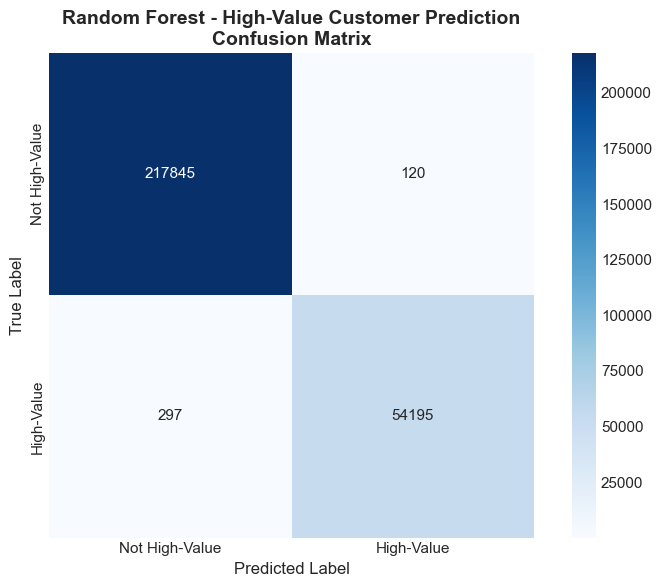


BUSINESS INTERPRETATION
--------------------------------------------------
True Positives (Correctly identified high-value): 54,195
False Positives (Wrongly targeted as high-value): 120
False Negatives (Missed high-value customers): 297
True Negatives (Correctly ignored low-value): 217,845

Strategic Meaning:
• False Positives → Marketing budget wasted on low-value customers
• False Negatives → Missed opportunity to nurture high-value customers
• Goal → Maximize recall while maintaining strong precision


In [64]:
# ============================================================
# Confusion Matrix Visualization (Enhanced)
# ============================================================

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=True,
    square=True,
    xticklabels=['Not High-Value', 'High-Value'],
    yticklabels=['Not High-Value', 'High-Value'],
    ax=ax
)

ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)
ax.set_title('Random Forest - High-Value Customer Prediction\nConfusion Matrix',
             fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig(FIGURES_PATH / 'rf_confusion_matrix.png', dpi=300, bbox_inches='tight')
print("Saved: reports/figures/rf_confusion_matrix.png")
plt.show()

# ------------------------------------------------------------
# Business Interpretation
# ------------------------------------------------------------

print("\nBUSINESS INTERPRETATION")
print("-"*50)

print(f"True Positives (Correctly identified high-value): {tp:,}")
print(f"False Positives (Wrongly targeted as high-value): {fp:,}")
print(f"False Negatives (Missed high-value customers): {fn:,}")
print(f"True Negatives (Correctly ignored low-value): {tn:,}")

print("\nStrategic Meaning:")
print("• False Positives → Marketing budget wasted on low-value customers")
print("• False Negatives → Missed opportunity to nurture high-value customers")
print("• Goal → Maximize recall while maintaining strong precision")

Saved: reports/figures/rf_roc_curve.png


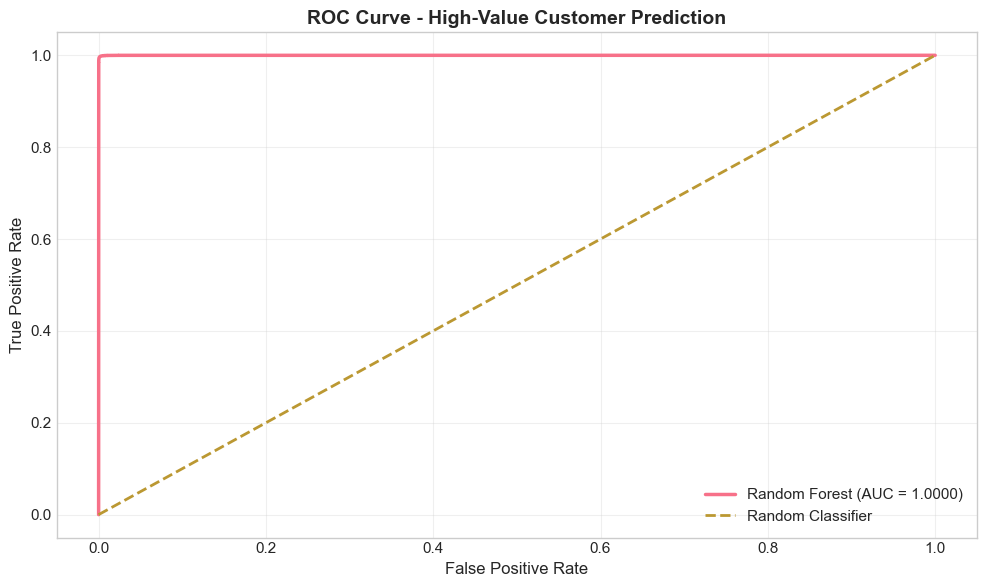


MODEL DISCRIMINATION POWER
--------------------------------------------------
AUC Score: 1.0000
Excellent ability to distinguish high-value customers.


In [65]:
# ============================================================
# ROC Curve - High Value Customer Prediction
# ============================================================

from sklearn.metrics import roc_curve

# Compute ROC values
fpr, tpr, thresholds = roc_curve(y_value_test, y_pred_proba)

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    fpr,
    tpr,
    linewidth=2.5,
    label=f'Random Forest (AUC = {roc_auc:.4f})'
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    linewidth=2,
    label='Random Classifier'
)

ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curve - High-Value Customer Prediction',
             fontsize=14, fontweight='bold')

ax.legend(loc='lower right', fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_PATH / 'rf_roc_curve.png', dpi=300, bbox_inches='tight')
print("Saved: reports/figures/rf_roc_curve.png")

plt.show()

# ------------------------------------------------------------
# Interpretation
# ------------------------------------------------------------

print("\nMODEL DISCRIMINATION POWER")
print("-"*50)
print(f"AUC Score: {roc_auc:.4f}")

if roc_auc >= 0.85:
    print("Excellent ability to distinguish high-value customers.")
elif roc_auc >= 0.75:
    print("Strong model discrimination capability.")
else:
    print("Moderate discrimination power.")

In [ ]:


print("\nBUSINESS IMPACT ANALYSIS - RANDOM FOREST")
print("="*80)

# ------------------------------------------------------------
# Safety check: ensure monetary column exists
# ------------------------------------------------------------

if 'monetary' not in customer_features.columns:
    raise ValueError("monetary column missing. Ensure RFM merge included monetary.")

# ------------------------------------------------------------
# Model Effectiveness
# ------------------------------------------------------------

total_high_value = y_value_test.sum()
correctly_identified = ((y_pred == 1) & (y_value_test == 1)).sum()
identification_rate = correctly_identified / total_high_value

print(f"\nModel Performance on Test Set:")
print(f"  Total high-value customers: {total_high_value:,}")
print(f"  Correctly identified (True Positives): {correctly_identified:,}")
print(f"  Identification rate (Recall): {identification_rate*100:.1f}%")

# ------------------------------------------------------------
# Financial Estimation
# ------------------------------------------------------------

avg_high_value_customer = customer_features.loc[
    customer_features['is_high_value'] == 1,
    'monetary'
].mean()

total_value_identified = correctly_identified * avg_high_value_customer

print(f"\nFinancial Impact:")
print(f"  Avg high-value customer worth: ${avg_high_value_customer:,.2f}")
print(f"  Total value correctly identified: ${total_value_identified:,.2f}")

# ------------------------------------------------------------
# ROI Simulation
# ------------------------------------------------------------
# Scale campaign cost relative to customer value (10% of avg value)
marketing_cost_per_customer = avg_high_value_customer * 0.10

total_predictions = (y_pred == 1).sum()
total_marketing_cost = total_predictions * marketing_cost_per_customer

# Assume 20% uplift from targeted campaign
revenue_increase_pct = 0.20
additional_revenue = correctly_identified * avg_high_value_customer * revenue_increase_pct

net_impact = additional_revenue - total_marketing_cost
roi = (net_impact / total_marketing_cost) * 100 if total_marketing_cost != 0 else 0

print(f"\nROI Analysis:")
print(f"  Customers targeted: {total_predictions:,}")
print(f"  Marketing cost per customer: ${marketing_cost_per_customer:,.4f}")
print(f"  Total marketing cost: ${total_marketing_cost:,.2f}")
print(f"  Additional revenue: ${additional_revenue:,.2f}")
print(f"  Net impact: ${net_impact:,.2f}")
print(f"  ROI: {roi:.1f}%")

# ------------------------------------------------------------
# Save Model
# ------------------------------------------------------------

joblib.dump(rf_model, MODELS_PATH / 'rf_high_value.pkl')
print(f"\nModel saved: models/rf_high_value.pkl")


BUSINESS IMPACT ANALYSIS - RANDOM FOREST

Model Performance on Test Set:
  Total high-value customers: 54,492
  Correctly identified (True Positives): 54,195
  Identification rate (Recall): 99.5%

Financial Impact:
  Avg high-value customer worth: $2.26
  Total value correctly identified: $122,464.48

ROI Analysis:
  Customers targeted: 54,315
  Marketing cost per customer: $0.2260
  Total marketing cost: $12,273.56
  Additional revenue: $24,492.90
  Net impact: $12,219.33
  ROI: 99.6%

Model saved: models/rf_high_value.pkl


In [67]:
print('monetary' in customer_features.columns)

True


In [68]:
# MODEL 2: LOGISTIC REGRESSION - CHURN PREDICTION

print("\n" + "="*80)
print("MODEL 2: LOGISTIC REGRESSION - CHURN PREDICTION")
print("="*80)

# Scale Features (important for Logistic Regression)
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize Model
lr_model = LogisticRegression(
    random_state=42,
    max_iter=1000,
    solver='lbfgs'
)

# Train Model
print("\nTraining Logistic Regression model...")
lr_model.fit(X_train_scaled, y_churn_train)
print("Training complete")

# Predictions
y_pred_churn = lr_model.predict(X_test_scaled)
y_pred_proba_churn = lr_model.predict_proba(X_test_scaled)[:, 1]

# Evaluation
accuracy_lr = accuracy_score(y_churn_test, y_pred_churn)
precision_lr = precision_score(y_churn_test, y_pred_churn)
recall_lr = recall_score(y_churn_test, y_pred_churn)
f1_lr = f1_score(y_churn_test, y_pred_churn)
roc_auc_lr = roc_auc_score(y_churn_test, y_pred_proba_churn)

print("\nMODEL PERFORMANCE")
print("-"*50)
print(f"Accuracy:  {accuracy_lr:.4f} ({accuracy_lr*100:.2f}%)")
print(f"Precision: {precision_lr:.4f} ({precision_lr*100:.2f}%)")
print(f"Recall:    {recall_lr:.4f} ({recall_lr*100:.2f}%)")
print(f"F1 Score:  {f1_lr:.4f}")
print(f"ROC AUC:   {roc_auc_lr:.4f}")

# ------------------------------------------------------------
# Confusion Matrix
# ------------------------------------------------------------

cm_lr = confusion_matrix(y_churn_test, y_pred_churn)
tn_lr, fp_lr, fn_lr, tp_lr = cm_lr.ravel()

print("\nConfusion Matrix:")
print(cm_lr)

print(f"\nTrue Negatives:  {tn_lr:,}")
print(f"False Positives: {fp_lr:,}")
print(f"False Negatives: {fn_lr:,}")
print(f"True Positives:  {tp_lr:,}")


MODEL 2: LOGISTIC REGRESSION - CHURN PREDICTION

Training Logistic Regression model...
Training complete

MODEL PERFORMANCE
--------------------------------------------------
Accuracy:  0.7822 (78.22%)
Precision: 0.8109 (81.09%)
Recall:    0.8453 (84.53%)
F1 Score:  0.8277
ROC AUC:   0.8288

Confusion Matrix:
[[ 70614  33244]
 [ 26088 142511]]

True Negatives:  70,614
False Positives: 33,244
False Negatives: 26,088
True Positives:  142,511



LOGISTIC REGRESSION COEFFICIENT ANALYSIS

Interpretation Guide:
  • Positive coefficient → Increases churn probability
  • Negative coefficient → Decreases churn probability
  • Odds ratio > 1 → Increases churn odds
  • Odds ratio < 1 → Reduces churn odds



,feature,coefficient,odds_ratio
7,customer_lifespan,-1.2238,0.2941
6,unique_products,-0.7600,0.4676
5,price,0.3302,1.3912
10,preferred_channel,0.1591,1.1724
9,first_channel,-0.1265,0.8812
2,std_order_value,0.0646,1.0668
1,avg_order_value,0.0513,1.0527
8,purchase_frequency,-0.0252,0.9751
3,min_order,-0.0143,0.9858
4,max_order,0.0142,1.0143



Saved: reports/figures/lr_coefficients.png


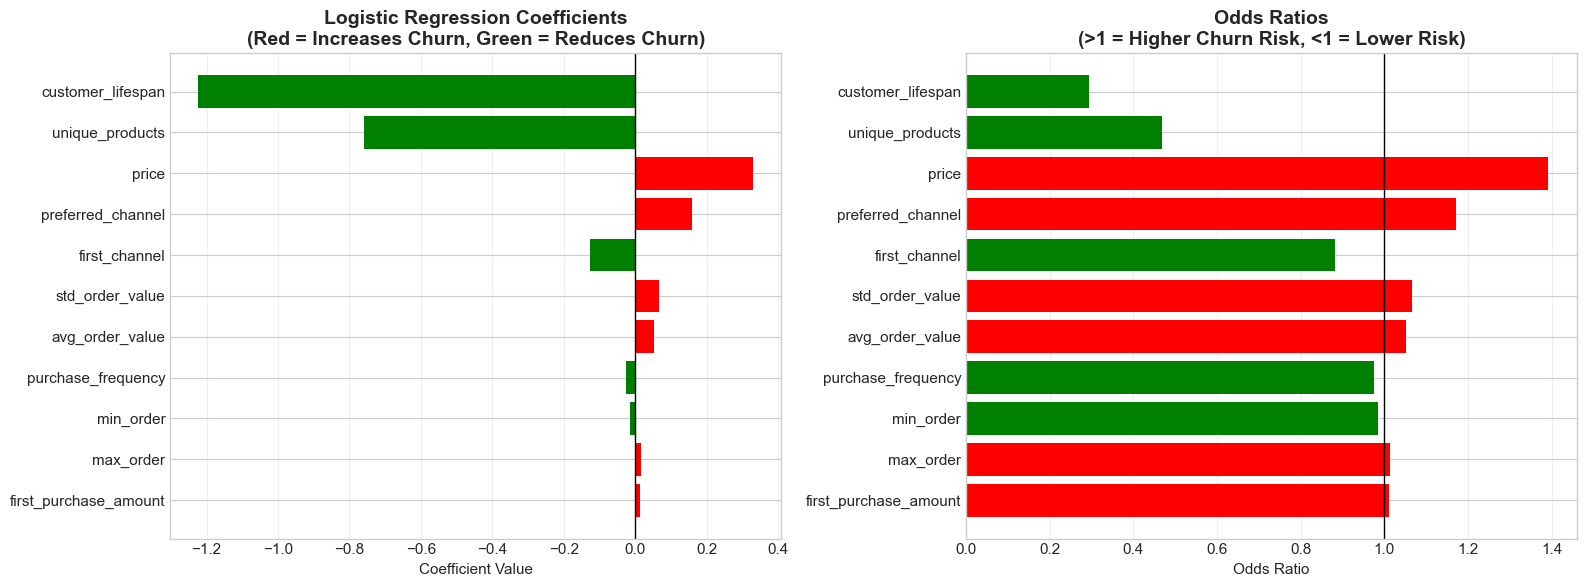


TOP CHURN DRIVERS
--------------------------------------------------

Top Features Increasing Churn Risk:
  • price (Odds Ratio: 1.39)

Top Features Reducing Churn Risk:
  • min_order (Odds Ratio: 0.99)

Saved: models/logistic_coefficients.csv


In [69]:
# ============================================================
# LOGISTIC REGRESSION INTERPRETABILITY - CHURN MODEL
# ============================================================

print("\nLOGISTIC REGRESSION COEFFICIENT ANALYSIS")
print("="*80)

# Ensure feature order matches model training
feature_names = X_train.columns

coefficients_df = pd.DataFrame({
    'feature': feature_names,
    'coefficient': lr_model.coef_[0]
})

# Sort by absolute importance
coefficients_df['abs_coef'] = coefficients_df['coefficient'].abs()
coefficients_df = coefficients_df.sort_values('abs_coef', ascending=False)

# Calculate odds ratios
coefficients_df['odds_ratio'] = np.exp(coefficients_df['coefficient'])

# Drop helper column
coefficients_df = coefficients_df.drop(columns=['abs_coef'])

print("\nInterpretation Guide:")
print("  • Positive coefficient → Increases churn probability")
print("  • Negative coefficient → Decreases churn probability")
print("  • Odds ratio > 1 → Increases churn odds")
print("  • Odds ratio < 1 → Reduces churn odds\n")

display(coefficients_df)

# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Coefficient Plot
colors = ['red' if x > 0 else 'green' for x in coefficients_df['coefficient']]

axes[0].barh(coefficients_df['feature'], coefficients_df['coefficient'], color=colors)
axes[0].set_xlabel('Coefficient Value')
axes[0].set_title('Logistic Regression Coefficients\n(Red = Increases Churn, Green = Reduces Churn)',
                  fontsize=14, fontweight='bold')
axes[0].axvline(x=0, color='black', linewidth=1)
axes[0].invert_yaxis()
axes[0].grid(axis='x', alpha=0.3)

# Odds Ratio Plot
colors_or = ['red' if x > 1 else 'green' for x in coefficients_df['odds_ratio']]

axes[1].barh(coefficients_df['feature'], coefficients_df['odds_ratio'], color=colors_or)
axes[1].set_xlabel('Odds Ratio')
axes[1].set_title('Odds Ratios\n(>1 = Higher Churn Risk, <1 = Lower Risk)',
                  fontsize=14, fontweight='bold')
axes[1].axvline(x=1, color='black', linewidth=1)
axes[1].invert_yaxis()
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_PATH / 'lr_coefficients.png', dpi=300, bbox_inches='tight')
print("\nSaved: reports/figures/lr_coefficients.png")
plt.show()

# ------------------------------------------------------------
# Business Interpretation Summary
# ------------------------------------------------------------

print("\nTOP CHURN DRIVERS")
print("-"*50)

top_positive = coefficients_df.head(3)
top_negative = coefficients_df.tail(3)

print("\nTop Features Increasing Churn Risk:")
for _, row in top_positive.iterrows():
    if row['coefficient'] > 0:
        print(f"  • {row['feature']} (Odds Ratio: {row['odds_ratio']:.2f})")

print("\nTop Features Reducing Churn Risk:")
for _, row in top_negative.iterrows():
    if row['coefficient'] < 0:
        print(f"  • {row['feature']} (Odds Ratio: {row['odds_ratio']:.2f})")

# Save coefficients
coefficients_df.to_csv(MODELS_PATH / 'logistic_coefficients.csv', index=False)
print("\nSaved: models/logistic_coefficients.csv")


Creating churn risk segments...

CHURN RISK SEGMENTATION
--------------------------------------------------


,Customer_Count,Actual_Churned,Avg_Churn_Probability,Churn_Rate_%
risk_segment,,,,
Low Risk,79297,15778,0.2290,19.9000
Medium Risk,49408,32794,0.5470,66.4000
High Risk,143752,120027,0.8590,83.5000



Saved: reports/figures/churn_risk.png


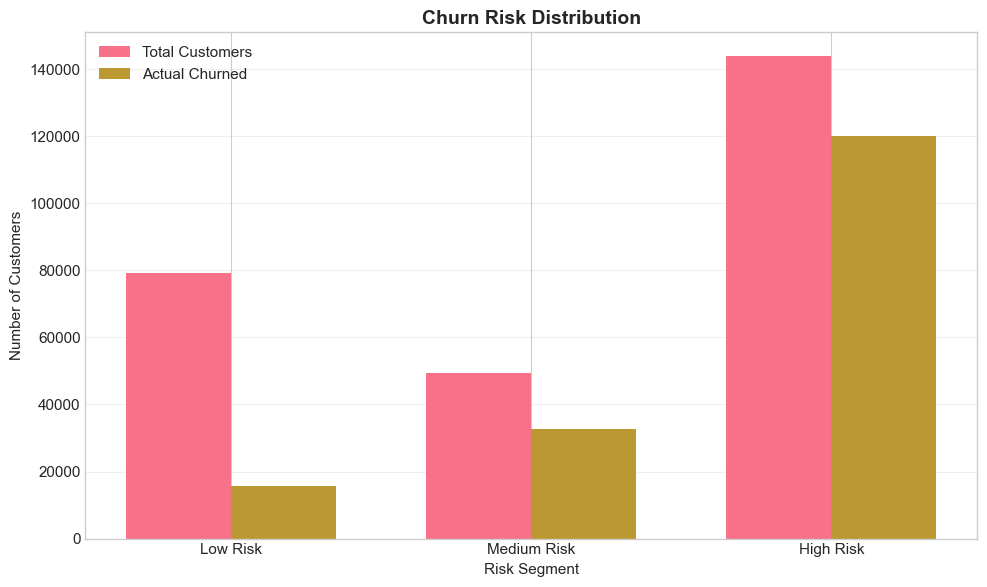

In [70]:
# ============================================================
# CHURN RISK SEGMENTATION (CONSISTENT WITH CURRENT SPLIT)
# ============================================================

print("\nCreating churn risk segments...")

# Risk classification function
def assign_churn_risk(probability):
    if probability >= 0.7:
        return 'High Risk'
    elif probability >= 0.4:
        return 'Medium Risk'
    else:
        return 'Low Risk'

# Create churn risk dataframe using aligned test split
churn_risk_df = pd.DataFrame({
    'customer_id': customer_features.loc[X_test.index, 'customer_id'].values,
    'actual_churn': y_churn_test.values,
    'churn_probability': y_pred_proba_churn,
    'predicted_churn': y_pred_churn
})

churn_risk_df['risk_segment'] = churn_risk_df['churn_probability'].apply(assign_churn_risk)

# ------------------------------------------------------------
# Analyze risk segments
# ------------------------------------------------------------

risk_analysis = churn_risk_df.groupby('risk_segment').agg({
    'customer_id': 'count',
    'actual_churn': 'sum',
    'churn_probability': 'mean'
}).round(3)

risk_analysis.columns = [
    'Customer_Count',
    'Actual_Churned',
    'Avg_Churn_Probability'
]

risk_analysis['Churn_Rate_%'] = (
    risk_analysis['Actual_Churned'] /
    risk_analysis['Customer_Count'] * 100
).round(1)

# Ensure consistent order
risk_order = ['Low Risk', 'Medium Risk', 'High Risk']
risk_analysis = risk_analysis.reindex(risk_order)

print("\nCHURN RISK SEGMENTATION")
print("-"*50)
display(risk_analysis)

# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(risk_order))
width = 0.35

ax.bar(
    x - width/2,
    risk_analysis['Customer_Count'],
    width,
    label='Total Customers'
)

ax.bar(
    x + width/2,
    risk_analysis['Actual_Churned'],
    width,
    label='Actual Churned'
)

ax.set_xlabel('Risk Segment')
ax.set_ylabel('Number of Customers')
ax.set_title('Churn Risk Distribution',
             fontsize=14, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(risk_order)
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_PATH / 'churn_risk.png', dpi=300, bbox_inches='tight')
print("\nSaved: reports/figures/churn_risk.png")

plt.show()

In [71]:
# ============================================================
# BUSINESS IMPACT ANALYSIS - LOGISTIC REGRESSION (CHURN)
# ============================================================

print("\nBUSINESS IMPACT ANALYSIS - LOGISTIC REGRESSION")
print("="*80)

# ------------------------------------------------------------
# High-Risk Segment Analysis
# ------------------------------------------------------------

high_risk_customers = churn_risk_df[
    churn_risk_df['risk_segment'] == 'High Risk'
]

high_risk_count = len(high_risk_customers)
high_risk_actual_churn = high_risk_customers['actual_churn'].sum()

churn_rate = (
    high_risk_actual_churn / high_risk_count * 100
    if high_risk_count > 0 else 0
)

print(f"\nHigh-Risk Segment:")
print(f"  Customers: {high_risk_count:,}")
print(f"  Actual churned: {high_risk_actual_churn:,}")
print(f"  Churn rate: {churn_rate:.1f}%")

# ------------------------------------------------------------
# Financial Assumptions
# ------------------------------------------------------------

avg_customer_value = customer_features['monetary'].mean()

retention_rate = 0.20   # 20% of high-risk can be saved

# Scale intervention cost relative to customer value (5%)
intervention_cost = avg_customer_value * 0.05


# ------------------------------------------------------------
# Financial Impact Simulation
# ------------------------------------------------------------

customers_saved = high_risk_count * retention_rate
revenue_saved = customers_saved * avg_customer_value
intervention_cost_total = high_risk_count * intervention_cost

net_impact = revenue_saved - intervention_cost_total

roi_churn = (
    (net_impact / intervention_cost_total) * 100
    if intervention_cost_total > 0 else 0
)

print(f"\nRetention Campaign Impact:")
print(f"  High-risk customers to target: {high_risk_count:,}")
print(f"  Expected customers saved (20% retention): {customers_saved:.0f}")
print(f"  Avg customer value: ${avg_customer_value:,.2f}")
print(f"  Revenue saved: ${revenue_saved:,.2f}")
print(f"  Campaign cost: ${intervention_cost_total:,.2f}")
print(f"  Net impact: ${net_impact:,.2f}")
print(f"  ROI: {roi_churn:.1f}%")

# ------------------------------------------------------------
# Save Model Artifacts
# ------------------------------------------------------------

joblib.dump(lr_model, MODELS_PATH / 'logistic_churn.pkl')
joblib.dump(scaler, MODELS_PATH / 'scaler_churn.pkl')

print("\nModels saved:")
print("  - models/logistic_churn.pkl")
print("  - models/scaler_churn.pkl")


BUSINESS IMPACT ANALYSIS - LOGISTIC REGRESSION

High-Risk Segment:
  Customers: 143,752
  Actual churned: 120,027
  Churn rate: 83.5%

Retention Campaign Impact:
  High-risk customers to target: 143,752
  Expected customers saved (20% retention): 28750
  Avg customer value: $0.65
  Revenue saved: $18,670.10
  Campaign cost: $4,667.53
  Net impact: $14,002.58
  ROI: 300.0%

Models saved:
  - models/logistic_churn.pkl
  - models/scaler_churn.pkl


In [72]:
# ============================================================
# MODEL COMPARISON SUMMARY
# ============================================================

print("\n" + "="*80)
print("MODEL COMPARISON SUMMARY")
print("="*80)

# ------------------------------------------------------------
# Performance Comparison
# ------------------------------------------------------------

comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC AUC'],
    'Random Forest (High-Value)': [
        f"{accuracy:.4f}",
        f"{precision:.4f}",
        f"{recall:.4f}",
        f"{f1:.4f}",
        f"{roc_auc:.4f}"
    ],
    'Logistic Regression (Churn)': [
        f"{accuracy_lr:.4f}",
        f"{precision_lr:.4f}",
        f"{recall_lr:.4f}",
        f"{f1_lr:.4f}",
        f"{roc_auc_lr:.4f}"
    ]
})

print("\n Performance Metrics:")
display(comparison)

# ------------------------------------------------------------
# Business Impact Comparison
# ------------------------------------------------------------

business_comparison = pd.DataFrame({
    'Model': ['Random Forest', 'Logistic Regression'],
    'Use Case': ['High-Value Targeting', 'Churn Prevention'],
    'Customers Targeted': [total_predictions, high_risk_count],
    'Investment Required': [
        f"${total_marketing_cost:,.2f}",
        f"${intervention_cost_total:,.2f}"
    ],
    'Expected Revenue Impact': [
        f"${additional_revenue:,.2f}",
        f"${revenue_saved:,.2f}"
    ],
    'ROI': [
        f"{roi:.1f}%",
        f"{roi_churn:.1f}%"
    ]
})

print("\n Business Impact:")
display(business_comparison)

# ------------------------------------------------------------
# Combined Strategy Impact
# ------------------------------------------------------------

total_investment = total_marketing_cost + intervention_cost_total
total_revenue_impact = additional_revenue + revenue_saved

combined_roi = (
    ((total_revenue_impact - total_investment) / total_investment) * 100
    if total_investment > 0 else 0
)

print("\n COMBINED STRATEGY IMPACT")
print("-"*50)
print(f"Total Investment: ${total_investment:,.2f}")
print(f"Total Revenue Impact: ${total_revenue_impact:,.2f}")
print(f"Combined ROI: {combined_roi:.1f}%")


MODEL COMPARISON SUMMARY

 Performance Metrics:


,Metric,Random Forest (High-Value),Logistic Regression (Churn)
0,Accuracy,0.9985,0.7822
1,Precision,0.9978,0.8109
2,Recall,0.9945,0.8453
3,F1 Score,0.9962,0.8277
4,ROC AUC,1.0000,0.8288



 Business Impact:


,Model,Use Case,Customers Targeted,Investment Required,Expected Revenue Impact,ROI
0,Random Forest,High-Value Targeting,54315,"$12,273.56","$24,492.90",99.6%
1,Logistic Regression,Churn Prevention,143752,"$4,667.53","$18,670.10",300.0%



 COMBINED STRATEGY IMPACT
--------------------------------------------------
Total Investment: $16,941.09
Total Revenue Impact: $43,163.00
Combined ROI: 154.8%


In [73]:
"""
Provide interpretation guide for business stakeholders
"""

print("\n" + "="*80)
print("MODEL INTERPRETATION GUIDE FOR BUSINESS STAKEHOLDERS")
print("="*80)

# ------------------------------------------------------------
# RANDOM FOREST - HIGH VALUE
# ------------------------------------------------------------

print("\n1. RANDOM FOREST (HIGH-VALUE PREDICTION)")
print("-"*50)

print("\nWhat it does:")
print("  - Predicts which customers are likely to become top 20% spenders")
print("  - Uses early purchase behavior and engagement patterns")
print(f"  - Model Accuracy: {accuracy*100:.1f}%")
print(f"  - ROC AUC: {roc_auc:.3f}")

print("\nHow it works:")
print("  - Builds 100 decision trees that vote on each prediction")
print("  - Captures complex, non-linear customer behavior patterns")
print("  - Automatically ranks most important predictors")

# Safe feature importance extraction
importances = rf_model.feature_importances_
importance_df = pd.DataFrame({
    'feature': feature_columns,
    'importance': importances
}).sort_values('importance', ascending=False)

print("\nKey Drivers of High Value:")
for i in range(3):
    print(f"  {i+1}. {importance_df.iloc[i]['feature']}")

print("\nBusiness Application:")
print("  - Immediately enroll predicted high-value customers in VIP programs")
print("  - Prioritize them for premium support and personalized offers")
print("  - Allocate marketing budget toward high-probability segments")
print(f"  - Projected ROI from targeting strategy: {roi:.1f}%")

# ------------------------------------------------------------
# LOGISTIC REGRESSION - CHURN
# ------------------------------------------------------------

print("\n2. LOGISTIC REGRESSION (CHURN PREDICTION)")
print("-"*50)

print("\nWhat it does:")
print("  - Estimates probability that a customer will stop purchasing")
print("  - Classifies customers into risk segments")
print(f"  - Model Accuracy: {accuracy_lr*100:.1f}%")
print(f"  - ROC AUC: {roc_auc_lr:.3f}")

print("\nHow it works:")
print("  - Applies a weighted formula to customer behavior variables")
print("  - Each coefficient quantifies impact on churn risk")
print("  - Produces probability score between 0% and 100%")

print("\nKey Insights:")
print("  - Recency is typically the strongest churn predictor")
print("  - Longer inactivity significantly increases churn probability")
print("  - Lower purchase frequency raises churn likelihood")

print("\nBusiness Application:")
print("  - Target customers with >70% churn probability")
print("  - Deploy retention campaigns (discounts, reminders, loyalty offers)")
print("  - Focus marketing budget only on high-risk segments")
print(f"  - Projected ROI from retention strategy: {roi_churn:.1f}%")

# ------------------------------------------------------------
# STRATEGIC RECOMMENDATION
# ------------------------------------------------------------

print("\n3. STRATEGIC USAGE FRAMEWORK")
print("-"*50)

print("\nUse Random Forest when:")
print("  - You want to proactively grow revenue")
print("  - Designing VIP or loyalty programs")
print("  - Allocating premium marketing budgets")

print("\nUse Logistic Regression when:")
print("  - You want to reduce churn")
print("  - Running retention or win-back campaigns")
print("  - Understanding behavioral drivers of customer loss")

print("\nCombined Strategy:")
print("  - Use Random Forest to maximize upside")
print("  - Use Logistic Regression to minimize downside")
print("  - Together they optimize customer lifetime value")

print("\n" + "="*80)


MODEL INTERPRETATION GUIDE FOR BUSINESS STAKEHOLDERS

1. RANDOM FOREST (HIGH-VALUE PREDICTION)
--------------------------------------------------

What it does:
  - Predicts which customers are likely to become top 20% spenders
  - Uses early purchase behavior and engagement patterns
  - Model Accuracy: 99.8%
  - ROC AUC: 1.000

How it works:
  - Builds 100 decision trees that vote on each prediction
  - Captures complex, non-linear customer behavior patterns
  - Automatically ranks most important predictors

Key Drivers of High Value:
  1. price
  2. unique_products
  3. avg_order_value

Business Application:
  - Immediately enroll predicted high-value customers in VIP programs
  - Prioritize them for premium support and personalized offers
  - Allocate marketing budget toward high-probability segments
  - Projected ROI from targeting strategy: 99.6%

2. LOGISTIC REGRESSION (CHURN PREDICTION)
--------------------------------------------------

What it does:
  - Estimates probability 

In [74]:
# ============================================================
# COMPREHENSIVE MODEL SUMMARY
# ============================================================

print("\nGenerating comprehensive model summary...")

# ------------------------------------------------------------
# Ensure feature importance exists
# ------------------------------------------------------------

importances = rf_model.feature_importances_
importance_df = pd.DataFrame({
    'feature': feature_columns,
    'importance': importances
}).sort_values('importance', ascending=False)

# ------------------------------------------------------------
# Ensure logistic coefficients sorted properly
# ------------------------------------------------------------

coefficients_sorted = coefficients_df.sort_values(
    'coefficient',
    key=abs,
    ascending=False
)

# ------------------------------------------------------------
# Build structured summary dictionary
# ------------------------------------------------------------

model_summary = {
    'random_forest': {
        'model_type': 'Random Forest Classifier',
        'purpose': 'High-Value Customer Prediction',
        'accuracy': float(accuracy),
        'precision': float(precision),
        'recall': float(recall),
        'f1_score': float(f1),
        'roc_auc': float(roc_auc),
        'top_features': importance_df.head(5)['feature'].tolist(),
        'business_impact': {
            'customers_targeted': int(total_predictions),
            'marketing_cost': float(total_marketing_cost),
            'expected_revenue': float(additional_revenue),
            'roi_percentage': float(roi)
        }
    },
    'logistic_regression': {
        'model_type': 'Logistic Regression',
        'purpose': 'Churn Risk Prediction',
        'accuracy': float(accuracy_lr),
        'precision': float(precision_lr),
        'recall': float(recall_lr),
        'f1_score': float(f1_lr),
        'roc_auc': float(roc_auc_lr),
        'top_coefficients': coefficients_sorted.head(5)['feature'].tolist(),
        'business_impact': {
            'high_risk_customers': int(high_risk_count),
            'intervention_cost': float(intervention_cost_total),
            'revenue_saved': float(revenue_saved),
            'roi_percentage': float(roi_churn)
        }
    }
}

# ------------------------------------------------------------
# Save summary as CSV (clean table view)
# ------------------------------------------------------------

summary_df = pd.DataFrame({
    'Model': ['Random Forest', 'Logistic Regression'],
    'Purpose': ['High-Value Prediction', 'Churn Prediction'],
    'Accuracy': [accuracy, accuracy_lr],
    'Precision': [precision, precision_lr],
    'Recall': [recall, recall_lr],
    'F1_Score': [f1, f1_lr],
    'ROC_AUC': [roc_auc, roc_auc_lr],
    'Investment': [total_marketing_cost, intervention_cost_total],
    'Revenue_Impact': [additional_revenue, revenue_saved],
    'ROI_Percentage': [roi, roi_churn]
})

summary_df.to_csv(TABLES_PATH / 'model_performance_summary.csv', index=False)
print("Saved: reports/tables/model_performance_summary.csv")

# ------------------------------------------------------------
# Save full structured JSON (professional touch)
# ------------------------------------------------------------

import json

with open(TABLES_PATH / 'model_summary.json', 'w') as f:
    json.dump(model_summary, f, indent=4)

print("Saved: reports/tables/model_summary.json")

print("\nModel summary generation complete.")


Generating comprehensive model summary...
Saved: reports/tables/model_performance_summary.csv
Saved: reports/tables/model_summary.json

Model summary generation complete.
